# Capítulo 8 — Exercício 10: visualização do MNIST

Vamos projetar as **primeiras 5.000 imagens do MNIST em duas dimensões** com t-SNE e comparar com PCA, LLE e MDS. Também representaremos exemplos por números e por miniaturas das imagens, controlando a sobreposição.

Os quatro métodos recebem as mesmas imagens. **Os rótulos não participam do ajuste**: servem apenas para colorir e interpretar os gráficos.

Referência: [notebook do autor, exercício 10](https://github.com/ageron/handson-ml3/blob/main/08_dimensionality_reduction.ipynb#10.).

## 1. Preparar o ambiente e a pasta de figuras

Fixamos a semente e limitamos o paralelismo para tornar o experimento reproduzível. Registramos versões e tempos medidos nesta execução. O MDS usa uma inicialização e até 300 iterações; ele pode levar alguns minutos porque trabalha com distâncias entre todos os pares de imagens.

As figuras serão salvas automaticamente em `images/exercicio_10`, relativamente ao diretório de execução do notebook.

In [1]:
import os
N_JOBS = 4
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = str(N_JOBS)

import platform
from pathlib import Path
from datetime import datetime
from time import perf_counter
from zoneinfo import ZoneInfo

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, LocallyLinearEmbedding, MDS, trustworthiness
from threadpoolctl import threadpool_limits

thread_limits = threadpool_limits(limits=N_JOBS)
RANDOM_STATE = 42
IMAGES_PATH = Path("images") / "exercicio_10"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)
executado_em = datetime.now(ZoneInfo("America/Recife")).isoformat(timespec="seconds")
print(f"Execução: {executado_em}")
print(f"Python {platform.python_version()} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")
print(f"Pasta das figuras: {IMAGES_PATH.resolve()}")

cmap = plt.get_cmap("tab10")
norm = BoundaryNorm(np.arange(-0.5, 10.5, 1), cmap.N)

def salvar_figura(nome):
    plt.savefig(IMAGES_PATH / f"{nome}.png", dpi=160, bbox_inches="tight")

Execução: 2026-10-19T16:57:57-03:00
Python 3.11.14 | NumPy 2.1.3 | scikit-learn 1.5.2
Pasta das figuras: /home/jorge/Documentos/livros/modelos-handson/chapter-08/images/exercicio_10


## 2. Selecionar as primeiras 5.000 imagens

Carregamos a mesma versão do MNIST usada na questão 9. Mantemos os pixels em sua escala original, convertidos para `float32`. Não fazemos PCA antes dos métodos não lineares neste experimento: comparamos as quatro projeções diretamente a partir dos mesmos 784 atributos.

In [2]:
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False, parser="auto")
X = X[:5_000].astype(np.float32)
y = y[:5_000].astype(np.uint8)
assert X.shape == (5_000, 784)
assert y.shape == (5_000,)
assert set(np.unique(y)) == set(range(10))
print(f"Imagens: {X.shape[0]} | Atributos: {X.shape[1]}")
display(pd.Series(y).value_counts().sort_index().rename_axis("Dígito").to_frame("Quantidade"))

Imagens: 5000 | Atributos: 784


,Quantidade
Dígito,
0,479
1,563
2,488
3,493
4,535
5,434
6,501
7,550
8,462


## 3. Definir a medição e a função de dispersão

Cronometramos somente `fit_transform()`, sem incluir carregamento ou criação dos gráficos. A mesma paleta associa cada cor ao mesmo dígito em todas as figuras. Os eixos representam coordenadas da projeção; não são pixels nem têm interpretação física.

In [3]:
projecoes = {}
tempos = {}
modelos = {}

def projetar(nome, modelo):
    inicio = perf_counter()
    Z = modelo.fit_transform(X)
    tempos[nome] = perf_counter() - inicio
    assert Z.shape == (5_000, 2)
    assert np.isfinite(Z).all()
    projecoes[nome] = Z
    modelos[nome] = modelo
    print(f"{nome}: {tempos[nome]:.2f} s")
    return Z

def dispersao(ax, Z, titulo):
    pontos = ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap=cmap, norm=norm,
                        s=7, alpha=0.65, linewidths=0)
    ax.set(title=titulo, xlabel="Coordenada 1", ylabel="Coordenada 2")
    return pontos

## 4. Aplicar t-SNE e visualizar as classes

O t-SNE procura preservar relações locais de similaridade. Usamos perplexidade 30, inicialização por PCA e até 1.000 iterações. A inicialização fornece posições iniciais; o ajuste continua usando os 784 atributos.

Cores misturadas podem revelar sobreposição entre classes na projeção. As distâncias entre grupos, o tamanho dos grupos e os espaços vazios não devem ser interpretados diretamente como distâncias, densidades ou separações no espaço original.

t-SNE: 7.30 s


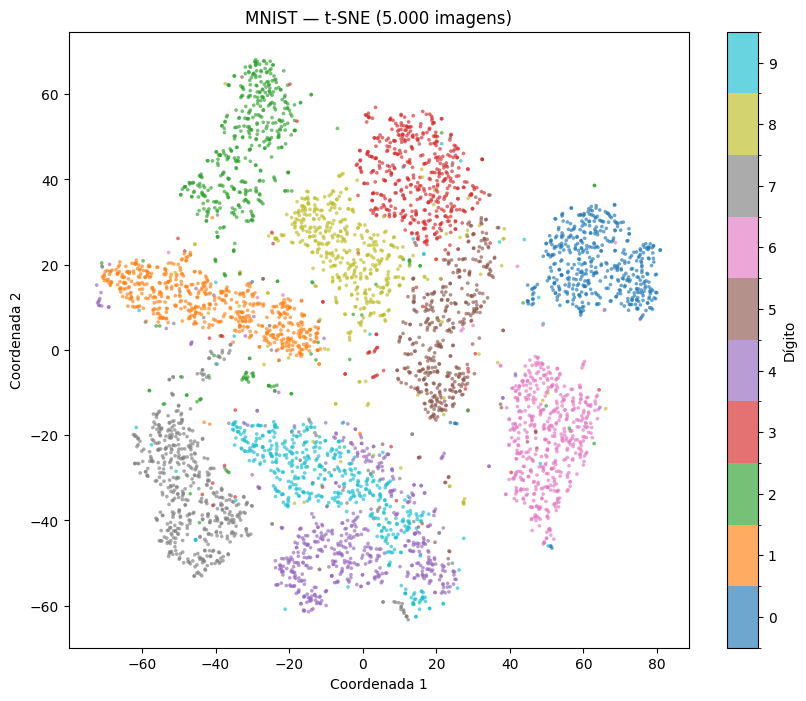

Divergência KL final: 1.4584


In [4]:
Z_tsne = projetar("t-SNE", TSNE(n_components=2, perplexity=30,
    init="pca", learning_rate="auto", max_iter=1000,
    random_state=RANDOM_STATE, n_jobs=N_JOBS))
fig, ax = plt.subplots(figsize=(10, 8))
pontos = dispersao(ax, Z_tsne, "MNIST — t-SNE (5.000 imagens)")
fig.colorbar(pontos, ax=ax, ticks=range(10), label="Dígito")
salvar_figura("tsne_dispersao")
plt.show()
print(f"Divergência KL final: {modelos['t-SNE'].kl_divergence_:.4f}")

## 5. Representar exemplos por números e miniaturas

Normalizamos apenas as coordenadas do desenho para o intervalo [0, 1]. Escolhemos exemplos em ordem aleatória e só adicionamos uma anotação se sua posição estiver suficientemente distante das já escolhidas. Isso reduz a sobreposição, sem modificar a projeção t-SNE.

O limite de anotações mantém a figura legível. A seleção serve à apresentação e não constitui uma amostra representativa das frequências das classes.

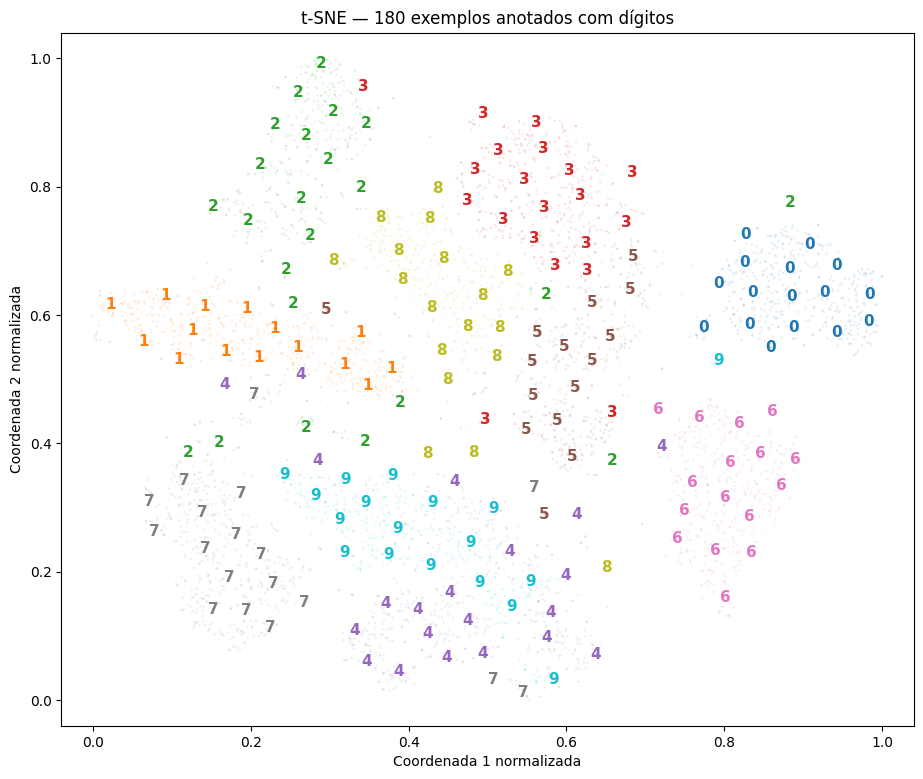

In [5]:
def selecionar_anotacoes(Z, distancia_minima=0.04, limite=180):
    amplitudes = np.ptp(Z, axis=0)
    coordenadas = (Z - Z.min(axis=0)) / np.maximum(amplitudes, 1e-12)
    selecionados = []
    rng = np.random.default_rng(RANDOM_STATE)
    for indice in rng.permutation(len(Z)):
        if selecionados:
            distancias = np.linalg.norm(coordenadas[selecionados] - coordenadas[indice], axis=1)
            if distancias.min() < distancia_minima:
                continue
        selecionados.append(indice)
        if len(selecionados) >= limite:
            break
    return coordenadas, selecionados

Z_desenho, indices_numeros = selecionar_anotacoes(Z_tsne)
fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(Z_desenho[:, 0], Z_desenho[:, 1], c=y, cmap=cmap, norm=norm,
           s=3, alpha=0.12, linewidths=0)
for indice in indices_numeros:
    ax.text(*Z_desenho[indice], str(y[indice]), color=cmap(int(y[indice])),
            fontsize=11, fontweight="bold", ha="center", va="center")
ax.set(xlim=(-0.04, 1.04), ylim=(-0.04, 1.04),
       title=f"t-SNE — {len(indices_numeros)} exemplos anotados com dígitos",
       xlabel="Coordenada 1 normalizada", ylabel="Coordenada 2 normalizada")
salvar_figura("tsne_numeros")
plt.show()

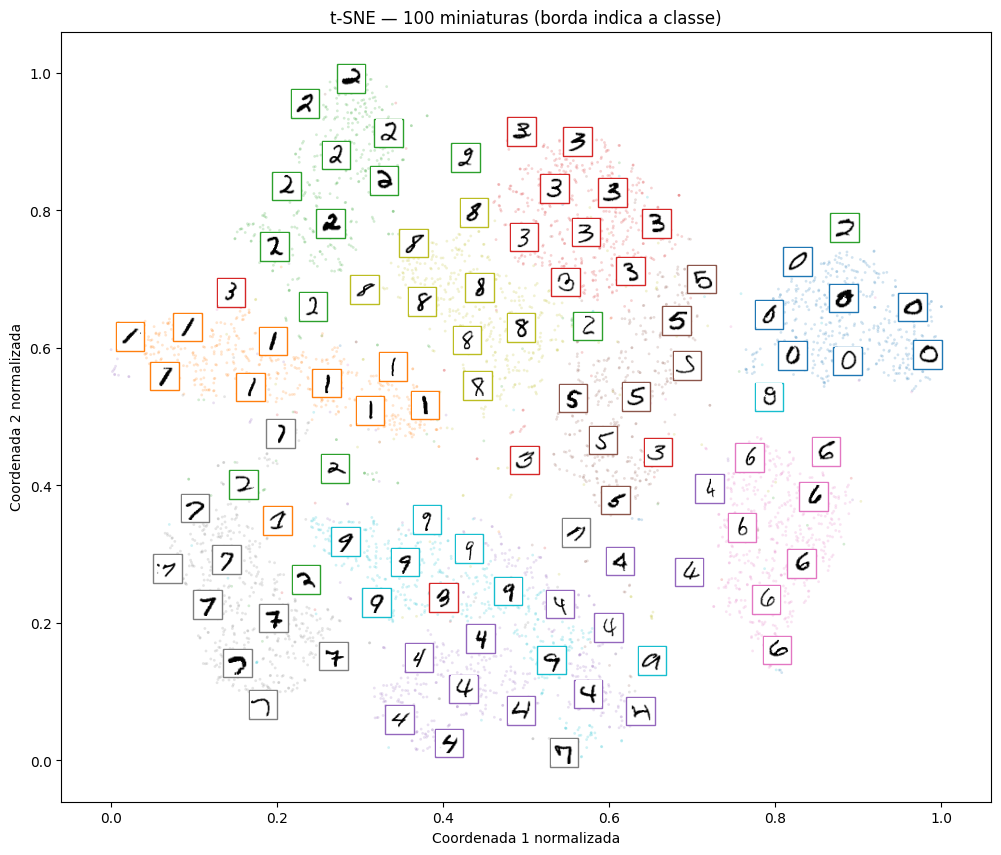

In [6]:
Z_desenho, indices_imagens = selecionar_anotacoes(Z_tsne, distancia_minima=0.065, limite=120)
fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(Z_desenho[:, 0], Z_desenho[:, 1], c=y, cmap=cmap, norm=norm,
           s=4, alpha=0.2, linewidths=0)
for indice in indices_imagens:
    imagem = OffsetImage(X[indice].reshape(28, 28), cmap="gray_r", zoom=0.65)
    caixa = AnnotationBbox(imagem, Z_desenho[indice], frameon=True, pad=0.12,
                          bboxprops=dict(edgecolor=cmap(int(y[indice])), linewidth=1))
    ax.add_artist(caixa)
ax.set(xlim=(-0.06, 1.06), ylim=(-0.06, 1.06),
       title=f"t-SNE — {len(indices_imagens)} miniaturas (borda indica a classe)",
       xlabel="Coordenada 1 normalizada", ylabel="Coordenada 2 normalizada")
salvar_figura("tsne_miniaturas")
plt.show()

## 6. Comparar PCA, LLE e MDS

- **PCA:** projeção linear que maximiza a variância preservada.
- **LLE:** tenta preservar relações de reconstrução entre vizinhos; usamos 10 vizinhos e o método padrão.
- **MDS métrico:** tenta preservar distâncias euclidianas entre pares. Usamos uma inicialização e no máximo 300 iterações para manter um orçamento explícito de execução.

Cada técnica otimiza um objetivo diferente. Uma figura com classes separadas é útil, mas não garante que toda a geometria dos dados tenha sido preservada.

In [7]:
Z_pca = projetar("PCA", PCA(n_components=2, svd_solver="full"))
print(f"Variância preservada em 2D pelo PCA: {modelos['PCA'].explained_variance_ratio_.sum():.2%}")

PCA: 0.17 s
Variância preservada em 2D pelo PCA: 17.27%


In [8]:
Z_lle = projetar("LLE", LocallyLinearEmbedding(n_components=2, n_neighbors=10,
    method="standard", eigen_solver="arpack", random_state=RANDOM_STATE, n_jobs=N_JOBS))

LLE: 2.68 s


In [9]:
Z_mds = projetar("MDS", MDS(n_components=2, metric=True, n_init=1,
    max_iter=300, eps=1e-3, normalized_stress=False,
    random_state=RANDOM_STATE, n_jobs=1))
print(f"Iterações do MDS: {modelos['MDS'].n_iter_}/300")
print(f"Stress bruto do MDS: {modelos['MDS'].stress_:.4e}")
if modelos["MDS"].n_iter_ == 300:
    print("O MDS atingiu o limite de iterações; o resultado pode melhorar com mais iterações ou inicializações.")

MDS: 79.61 s
Iterações do MDS: 300/300
Stress bruto do MDS: 1.1085e+13
O MDS atingiu o limite de iterações; o resultado pode melhorar com mais iterações ou inicializações.


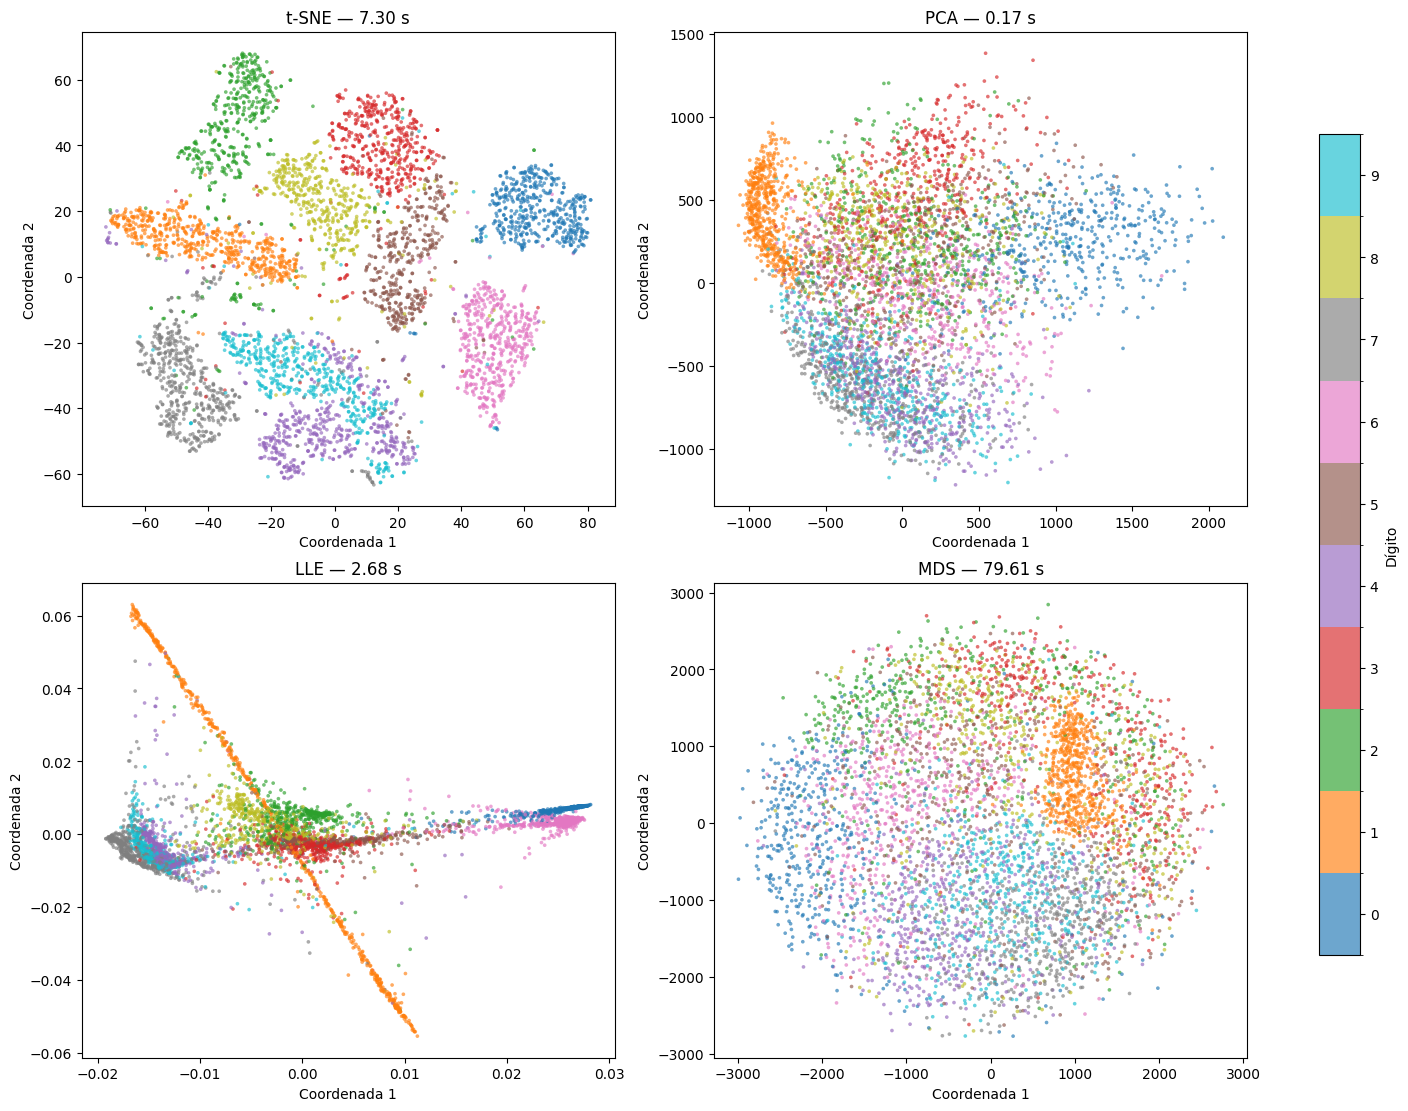

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
for ax, nome in zip(axes.ravel(), ("t-SNE", "PCA", "LLE", "MDS")):
    pontos = dispersao(ax, projecoes[nome], f"{nome} — {tempos[nome]:.2f} s")
fig.colorbar(pontos, ax=list(axes.ravel()), ticks=range(10), label="Dígito", shrink=0.8)
salvar_figura("comparacao_metodos")
plt.show()

## 7. Complementar a inspeção visual com uma medida de vizinhança

Calculamos **trustworthiness** com 10 vizinhos em uma amostra fixa e aleatória de 1.000 das 5.000 imagens. As projeções continuam sendo ajustadas nas 5.000 imagens; apenas a avaliação usa a amostra para limitar o custo.

Essa medida fica entre 0 e 1 e penaliza vizinhos que aparecem próximos na projeção, mas não eram próximos no espaço original. Valores maiores são melhores nesse critério. Ela não usa os rótulos e não mede acurácia de classificação nem preservação de toda a estrutura global. Os tempos abaixo excluem essa avaliação.

In [11]:
indices_avaliacao = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(X), size=1000, replace=False))
registros = []
for nome in ("t-SNE", "PCA", "LLE", "MDS"):
    qualidade = trustworthiness(X[indices_avaliacao], projecoes[nome][indices_avaliacao], n_neighbors=10)
    registros.append({"Método": nome, "Tempo (s)": tempos[nome], "Trustworthiness": qualidade})
tabela = pd.DataFrame(registros)
display(tabela.round(4))

,Método,Tempo (s),Trustworthiness
0,t-SNE,7.2957,0.9532
1,PCA,0.1668,0.7429
2,LLE,2.6757,0.8126
3,MDS,79.6146,0.7981


## 8. Registrar os resultados

A tabela e os links abaixo são gerados a partir desta execução. Consulte a comparação visual e as miniaturas para interpretar o resultado. A escolha dos parâmetros não foi otimizada; outros ajustes podem modificar as projeções.

In [12]:
linhas = [
    "Implementação passo a passo e saídas completas: [08_exercicio_10.ipynb](08_exercicio_10.ipynb).",
    "",
    f"Execução em {executado_em}, com Python {platform.python_version()}, NumPy {np.__version__} e scikit-learn {sklearn.__version__}. Foram usadas as **primeiras 5.000 imagens do MNIST**, com 784 pixels em `float32`, sem padronização adicional. Todos os métodos geraram duas coordenadas, sem usar os rótulos no ajuste.",
    "",
    "| Método | Tempo de ajuste e transformação (s) | Trustworthiness (10 vizinhos) |",
    "| --- | ---: | ---: |",
]
for _, r in tabela.iterrows():
    linhas.append(f"| {r['Método']} | {r['Tempo (s)']:.2f} | {r['Trustworthiness']:.4f} |")
linhas += ["", "A qualidade de vizinhança foi medida na mesma amostra aleatória de 1.000 imagens para todos os métodos (semente 42); os ajustes usaram as 5.000 imagens. Tempos de carregamento, avaliação e criação das figuras não estão incluídos. Os números representam uma única execução.", "",
    f"O PCA em 2D preservou **{modelos['PCA'].explained_variance_ratio_.sum():.2%}** da variância. O t-SNE usou perplexidade 30, inicialização por PCA, taxa de aprendizado automática e até 1.000 iterações. O LLE usou 10 vizinhos e o método padrão. O MDS métrico usou uma inicialização, até 300 iterações e `eps=1e-3`, executando **{modelos['MDS'].n_iter_} iterações**. t-SNE, LLE e MDS usaram `random_state=42`. O paralelismo foi limitado a quatro threads, com uma inicialização sequencial no MDS.", ""]
if modelos["MDS"].n_iter_ == 300:
    linhas += ["**Limitação do MDS:** o ajuste atingiu o limite de 300 iterações. Mais iterações ou outras inicializações podem mudar seu resultado; esta comparação usa a configuração declarada.", ""]
melhor = tabela.loc[tabela["Trustworthiness"].idxmax(), "Método"]
linhas += [f"Nesta execução, **{melhor}** apresentou a maior trustworthiness entre as configurações avaliadas. Essa medida avalia vizinhanças, não a separação de classes nem a acurácia de um classificador.", "",
    f"Foram criadas visualizações t-SNE com cores, **{len(indices_numeros)} anotações numéricas** e **{len(indices_imagens)} miniaturas**, escolhidas com uma distância mínima entre anotações para reduzir a sobreposição.", "",
    "![Comparação de t-SNE, PCA, LLE e MDS](images/exercicio_10/comparacao_metodos.png)", "",
    "![Miniaturas do MNIST na projeção t-SNE](images/exercicio_10/tsne_miniaturas.png)", "",
    "Outras figuras: [dispersão t-SNE](images/exercicio_10/tsne_dispersao.png) e [anotações numéricas](images/exercicio_10/tsne_numeros.png).", "",
    "**Interpretação:** o t-SNE enfatiza relações locais; não devemos interpretar diretamente distâncias entre grupos ou seus tamanhos como propriedades do espaço original. A projeção PCA em duas dimensões pode descartar muita variância. LLE e MDS preservam outros aspectos geométricos e não foram projetados para separar as dez classes. A escolha do método deve considerar o objetivo da visualização, sua qualidade e seu custo."]
resumo_markdown = "\n".join(linhas)
display(Markdown(resumo_markdown))

Implementação passo a passo e saídas completas: [08_exercicio_10.ipynb](08_exercicio_10.ipynb).

Execução em 2026-10-19T16:57:57-03:00, com Python 3.11.14, NumPy 2.1.3 e scikit-learn 1.5.2. Foram usadas as **primeiras 5.000 imagens do MNIST**, com 784 pixels em `float32`, sem padronização adicional. Todos os métodos geraram duas coordenadas, sem usar os rótulos no ajuste.

| Método | Tempo de ajuste e transformação (s) | Trustworthiness (10 vizinhos) |
| --- | ---: | ---: |
| t-SNE | 7.30 | 0.9532 |
| PCA | 0.17 | 0.7429 |
| LLE | 2.68 | 0.8126 |
| MDS | 79.61 | 0.7981 |

A qualidade de vizinhança foi medida na mesma amostra aleatória de 1.000 imagens para todos os métodos (semente 42); os ajustes usaram as 5.000 imagens. Tempos de carregamento, avaliação e criação das figuras não estão incluídos. Os números representam uma única execução.

O PCA em 2D preservou **17.27%** da variância. O t-SNE usou perplexidade 30, inicialização por PCA, taxa de aprendizado automática e até 1.000 iterações. O LLE usou 10 vizinhos e o método padrão. O MDS métrico usou uma inicialização, até 300 iterações e `eps=1e-3`, executando **300 iterações**. t-SNE, LLE e MDS usaram `random_state=42`. O paralelismo foi limitado a quatro threads, com uma inicialização sequencial no MDS.

**Limitação do MDS:** o ajuste atingiu o limite de 300 iterações. Mais iterações ou outras inicializações podem mudar seu resultado; esta comparação usa a configuração declarada.

Nesta execução, **t-SNE** apresentou a maior trustworthiness entre as configurações avaliadas. Essa medida avalia vizinhanças, não a separação de classes nem a acurácia de um classificador.

Foram criadas visualizações t-SNE com cores, **180 anotações numéricas** e **100 miniaturas**, escolhidas com uma distância mínima entre anotações para reduzir a sobreposição.

![Comparação de t-SNE, PCA, LLE e MDS](images/exercicio_10/comparacao_metodos.png)

![Miniaturas do MNIST na projeção t-SNE](images/exercicio_10/tsne_miniaturas.png)

Outras figuras: [dispersão t-SNE](images/exercicio_10/tsne_dispersao.png) e [anotações numéricas](images/exercicio_10/tsne_numeros.png).

**Interpretação:** o t-SNE enfatiza relações locais; não devemos interpretar diretamente distâncias entre grupos ou seus tamanhos como propriedades do espaço original. A projeção PCA em duas dimensões pode descartar muita variância. LLE e MDS preservam outros aspectos geométricos e não foram projetados para separar as dez classes. A escolha do método deve considerar o objetivo da visualização, sua qualidade e seu custo.

### Leitura dos gráficos desta execução

O t-SNE mostrou grupos mais distinguíveis visualmente, embora ainda existam misturas, como entre 4 e 9 e entre 3 e 5. As miniaturas permitem inspecionar estilos de escrita e exemplos que aparecem próximos de outras classes.

No PCA e no MDS, várias cores se sobrepõem intensamente. No LLE, alguns grupos aparecem em braços alongados, mas há forte mistura na região central. Portanto, nesta configuração, o t-SNE foi a opção mais informativa para explorar visualmente as classes. Essa observação visual é compatível com sua maior trustworthiness, mas as duas avaliações medem aspectos diferentes.